# The Android app market on Google Play

An exploratory analysis of about 9,700 apps scraped from the Google Play store, plus a sample of user reviews with pre-computed sentiment scores. The questions:

- Which categories have the most apps, and which get the most installs?
- How are ratings distributed?
- Do size and price relate to rating?
- How are paid apps priced, and how do they compare with free apps on installs and review sentiment?

Data: `datasets/apps.csv` and `datasets/user_reviews.csv`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

apps = pd.read_csv("datasets/apps.csv", index_col=0).drop_duplicates()
print("Number of apps:", len(apps))
apps.sample(5, random_state=1)

Number of apps: 9659


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
2358,VitusVet: Pet Health Care App,MEDICAL,4.8,3052,12.0,"100,000+",Free,0,Everyone,Medical,"July 31, 2018",3.8.0,4.1 and up
2338,Drugs.com Medication Guide,MEDICAL,4.4,15875,NaN,"1,000,000+",Free,0,Everyone,Medical,"May 22, 2018",Varies with device,4.4 and up
3521,Smart File Manager,PRODUCTIVITY,4.2,17415,4.1,"1,000,000+",Free,0,Everyone,Productivity,"July 5, 2018",3.5.9,4.0 and up
2759,MiniInTheBox Online Shopping,SHOPPING,3.9,34171,NaN,"1,000,000+",Free,0,Everyone,Shopping,"July 24, 2018",Varies with device,Varies with device
9940,eu sou franky,BUSINESS,3.7,195,4.0,"10,000+",Free,0,Everyone,Business,"November 21, 2016",1.0.1,4.0 and up


## 1. Cleaning

`Installs` and `Price` are stored as text (`"10,000+"`, `"$4.99"`). The symbols are stripped and both columns converted to numbers. Note that `Installs` is a lower bound for a bracket, not an exact count.

In [2]:
for col in ["Installs", "Price"]:
    apps[col] = apps[col].str.replace(r"[+,$]", "", regex=True).astype(float)

apps[["Rating", "Reviews", "Size", "Installs", "Price"]].describe().round(2)

,Rating,Reviews,Size,Installs,Price
count,8196.00,9659.00,8432.00,9.659000e+03,9659.00
mean,4.17,216592.56,20.40,7.777507e+06,1.10
std,0.54,1831319.57,21.83,5.375828e+07,16.85
min,1.00,0.00,0.00,0.000000e+00,0.00
25%,4.00,25.00,4.60,1.000000e+03,0.00
50%,4.30,967.00,12.00,1.000000e+05,0.00
75%,4.50,29401.00,28.00,1.000000e+06,0.00
max,5.00,78158306.00,100.00,1.000000e+09,400.00


In [3]:
apps.isna().sum()[lambda s: s > 0]

Rating         1463
Size           1227
Current Ver       8
Android Ver       2
dtype: int64

About 15% of apps have no rating and 13% have no size (listed as "Varies with device"). They are kept, and dropped only in the analyses that need those columns.

## 2. Categories

Number of categories: 33


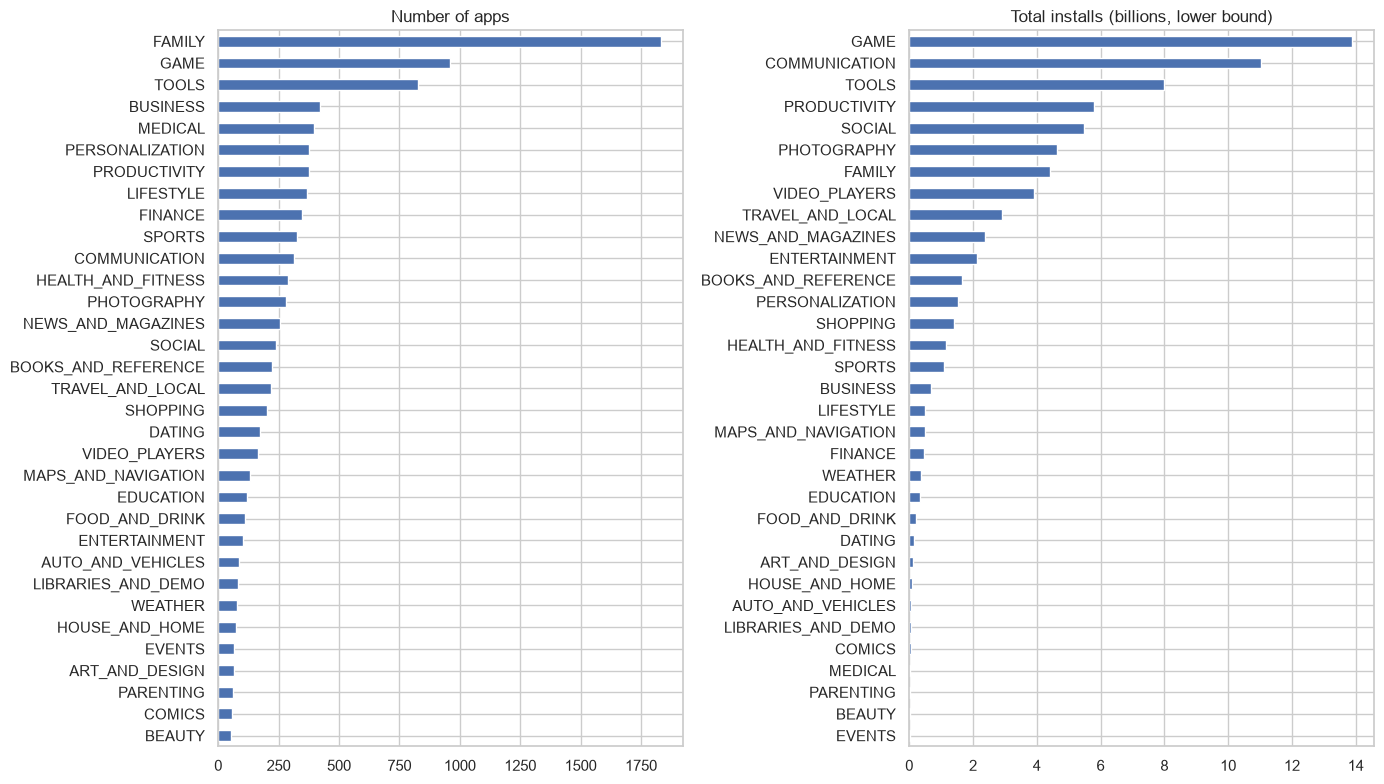

In [4]:
by_category = apps.groupby("Category").agg(apps=("App", "count"), installs=("Installs", "sum"))
print("Number of categories:", len(by_category))

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
by_category["apps"].sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Number of apps")
axes[0].set_ylabel("")
(by_category["installs"] / 1e9).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Total installs (billions, lower bound)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

In [5]:
by_category.assign(share_of_apps_pct=lambda d: (d["apps"] / d["apps"].sum() * 100).round(1),
                   share_of_installs_pct=lambda d: (d["installs"] / d["installs"].sum() * 100).round(1)
                   ).sort_values("apps", ascending=False).head(8)[["apps", "share_of_apps_pct", "share_of_installs_pct"]]

,apps,share_of_apps_pct,share_of_installs_pct
Category,,,
FAMILY,1832,19.0,5.9
GAME,959,9.9,18.5
TOOLS,827,8.6,10.7
BUSINESS,420,4.3,0.9
MEDICAL,395,4.1,0.1
PERSONALIZATION,376,3.9,2.0
PRODUCTIVITY,374,3.9,7.7
LIFESTYLE,369,3.8,0.7


## 3. Ratings

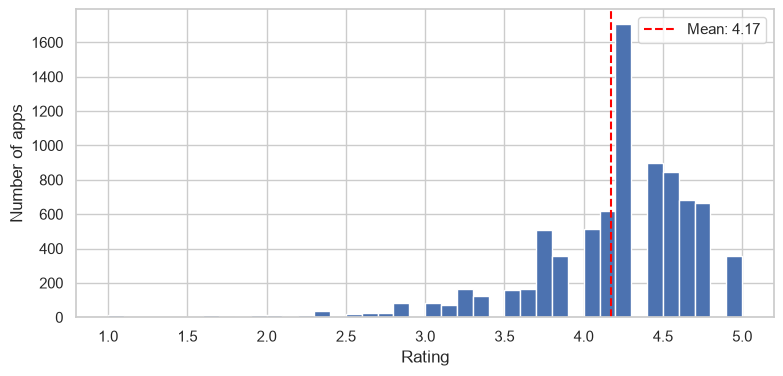

Share of rated apps with 4.0 or higher: 76.7%


In [6]:
avg_app_rating = apps["Rating"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(apps["Rating"].dropna(), bins=40)
ax.axvline(avg_app_rating, color="red", linestyle="--", label=f"Mean: {avg_app_rating:.2f}")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of apps")
ax.legend()
plt.show()

print(f"Share of rated apps with 4.0 or higher: {(apps['Rating'].dropna() >= 4).mean():.1%}")

## 4. Size, price and rating

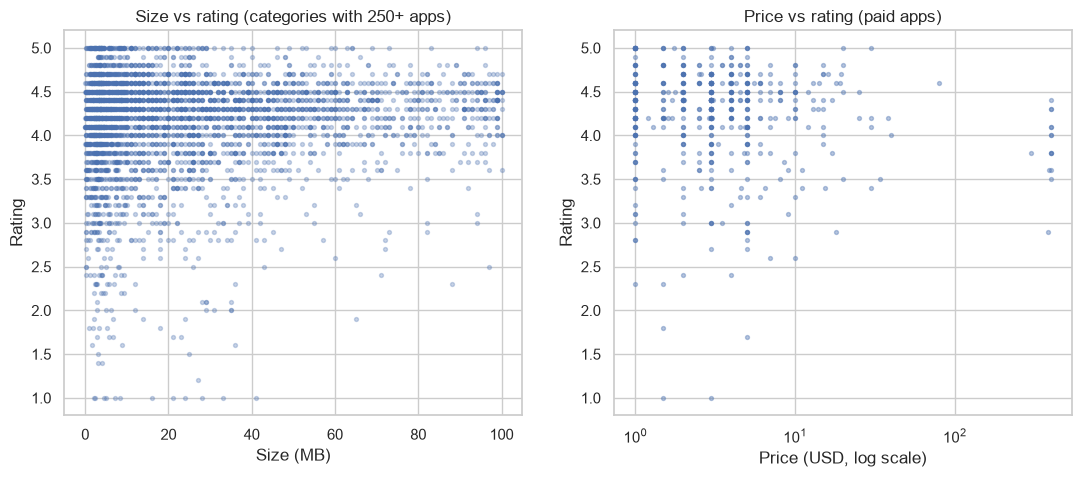

Correlation of size and rating:  0.08
Correlation of price and rating: -0.11
Paid apps priced under $10: 89.6%


In [7]:
rated = apps.dropna(subset=["Rating", "Size"])
large_categories = rated.groupby("Category").filter(lambda x: len(x) >= 250)
paid_apps = rated[rated["Type"] == "Paid"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(large_categories["Size"], large_categories["Rating"], s=8, alpha=0.3)
axes[0].set_xlabel("Size (MB)")
axes[0].set_ylabel("Rating")
axes[0].set_title("Size vs rating (categories with 250+ apps)")
axes[1].scatter(paid_apps["Price"], paid_apps["Rating"], s=8, alpha=0.4)
axes[1].set_xscale("log")
axes[1].set_xlabel("Price (USD, log scale)")
axes[1].set_ylabel("Rating")
axes[1].set_title("Price vs rating (paid apps)")
plt.show()

print(f"Correlation of size and rating:  {large_categories['Size'].corr(large_categories['Rating']):.2f}")
print(f"Correlation of price and rating: {paid_apps['Price'].corr(paid_apps['Rating']):.2f}")
print(f"Paid apps priced under $10: {(paid_apps['Price'] < 10).mean():.1%}")

## 5. Pricing by category

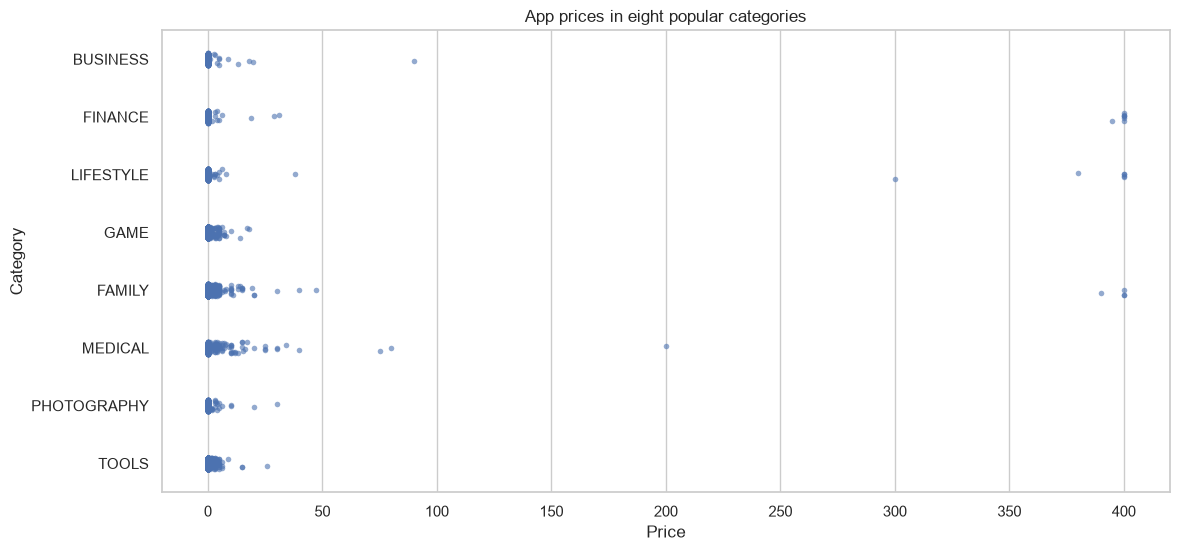

,Category,App,Price
4197,FAMILY,most expensive app (H),399.99
4362,LIFESTYLE,💎 I'm rich,399.99
4367,LIFESTYLE,I'm Rich - Trump Edition,400.00
5351,LIFESTYLE,I am rich,399.99
5354,FAMILY,I am Rich Plus,399.99
5355,LIFESTYLE,I am rich VIP,299.99
5356,FINANCE,I Am Rich Premium,399.99
5357,LIFESTYLE,I am extremely Rich,379.99
5358,FINANCE,I am Rich!,399.99
5359,FINANCE,I am rich(premium),399.99


In [8]:
popular = ["GAME", "FAMILY", "PHOTOGRAPHY", "MEDICAL", "TOOLS", "FINANCE", "LIFESTYLE", "BUSINESS"]
popular_app_cats = apps[apps["Category"].isin(popular)]

fig, ax = plt.subplots(figsize=(13, 6))
sns.stripplot(x="Price", y="Category", data=popular_app_cats, jitter=True, size=4, alpha=0.6, ax=ax)
ax.set_title("App prices in eight popular categories")
plt.show()

popular_app_cats.loc[popular_app_cats["Price"] > 200, ["Category", "App", "Price"]]

Everything above $200 is a novelty "I am rich" app rather than a real product. With apps over $100 removed, the real price range is visible:

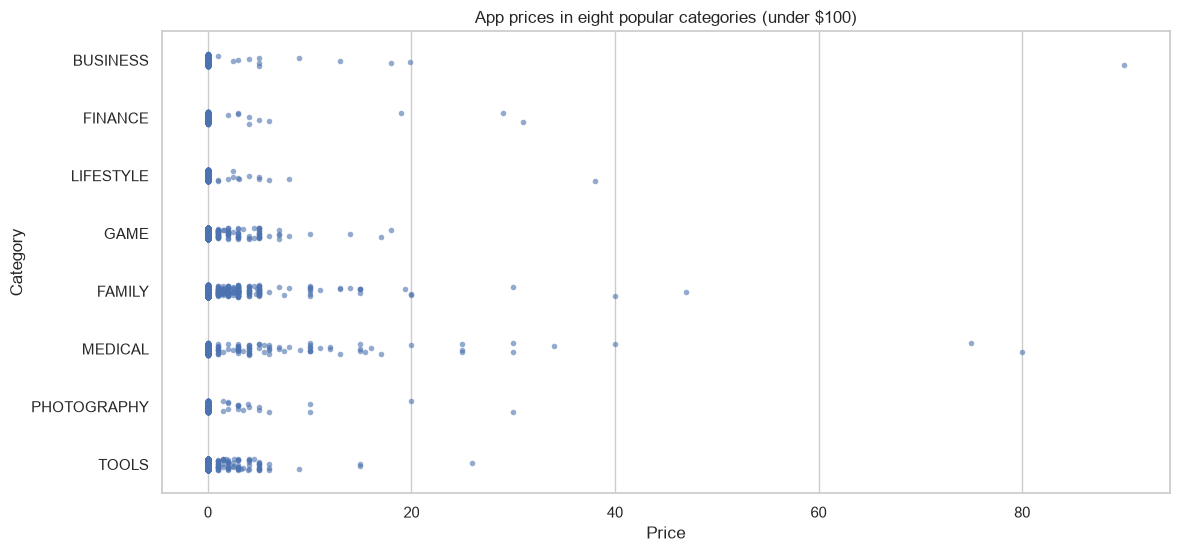

,count,median,max
Category,,,
BUSINESS,12,4.99,89.99
MEDICAL,82,4.99,79.99
FINANCE,10,4.49,30.99
PHOTOGRAPHY,19,3.49,29.99
LIFESTYLE,13,3.04,37.99
FAMILY,179,2.99,46.99
TOOLS,78,2.77,25.99
GAME,82,2.74,17.99


In [9]:
apps_under_100 = popular_app_cats[popular_app_cats["Price"] < 100]

fig, ax = plt.subplots(figsize=(13, 6))
sns.stripplot(x="Price", y="Category", data=apps_under_100, jitter=True, size=4, alpha=0.6, ax=ax)
ax.set_title("App prices in eight popular categories (under $100)")
plt.show()

paid_under_100 = apps_under_100[apps_under_100["Type"] == "Paid"]
paid_under_100.groupby("Category")["Price"].agg(["count", "median", "max"]).sort_values("median", ascending=False)

## 6. Paid vs free: installs

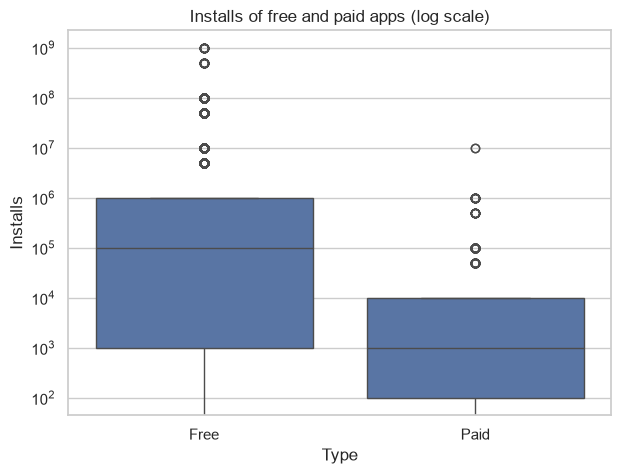

,count,median,mean
Type,,,
Free,8903,100000.0,8431492.0
Paid,756,1000.0,75879.0


In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(x="Type", y="Installs", data=apps.dropna(subset=["Type"]), ax=ax)
ax.set_yscale("log")
ax.set_title("Installs of free and paid apps (log scale)")
plt.show()

apps.groupby("Type")["Installs"].agg(["count", "median", "mean"]).round(0)

## 7. Paid vs free: review sentiment

`user_reviews.csv` has up to 100 reviews per app, each with a sentiment polarity score from -1 (negative) to 1 (positive).

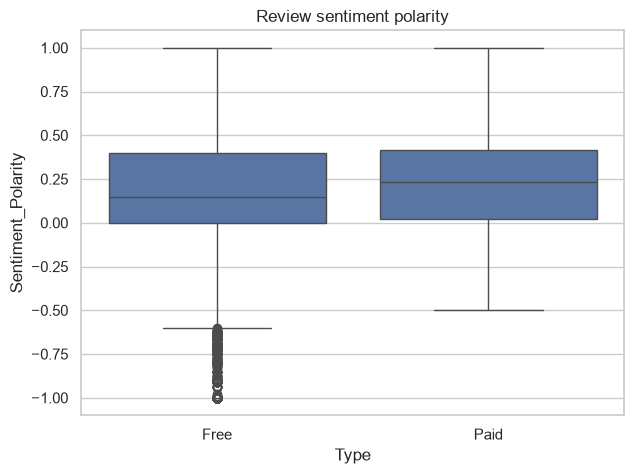

,apps,reviews,median_polarity,share_negative_pct
Type,,,,
Free,807,35513,0.15,22.36
Paid,9,416,0.23,15.14


In [11]:
reviews_df = pd.read_csv("datasets/user_reviews.csv")
merged_df = pd.merge(apps, reviews_df, on="App").dropna(subset=["Sentiment", "Review"])

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(x="Type", y="Sentiment_Polarity", data=merged_df, ax=ax)
ax.set_title("Review sentiment polarity")
plt.show()

summary = merged_df.groupby("Type").agg(
    apps=("App", "nunique"),
    reviews=("Review", "count"),
    median_polarity=("Sentiment_Polarity", "median"),
    share_negative_pct=("Sentiment", lambda s: (s == "Negative").mean() * 100),
).round(2)
summary

## Findings

- **Categories:** Family (19% of apps), Game (10%) and Tools (9%) are the most crowded of the 33 categories. Supply and demand do not line up: Game has 10% of the apps but about 18% of installs, while Family has 19% of the apps and 6% of installs. Medical and Business have many apps and very few installs.
- **Ratings:** the mean rating is 4.17 and 77% of rated apps score 4.0 or higher, so a rating in the low 4s is average rather than good.
- **Size and price:** neither has a meaningful relationship with rating (correlations of 0.08 and -0.11). Around 90% of paid apps cost less than $10.
- **Pricing by category:** Medical and Business apps have the highest typical prices (median $4.99, with some up to $80-90); games are the cheapest (median $2.74, nothing above $18). Everything above $200 is a novelty "I am rich" app.
- **Paid vs free:** the median free app has 100,000+ installs, against 1,000+ for the median paid app.
- **Sentiment:** reviews of paid apps are slightly more positive and less often negative (15% against 22%), but that comparison rests on only nine paid apps with review data, so it is suggestive at best.

Caveats: install counts are bracket lower bounds, and the review sample covers under a tenth of the apps.